# 281. Botryllus proteins that kmerseek links to MHC, histocompatibility and self/non-self recognition proteins

**Question.** Which *Botryllus schlosseri* proteins does kmerseek put a region on in a
Swiss-Prot protein of the MHC system, histocompatibility, or self/non-self recognition, and
which of those links do phmmer, jackhmmer and mmseqs2 all miss? Written for Ayelet, whose
interest is the MHC system, histocompatibility, self/non-self recognition and
allorecognition (one colony telling a genetically different colony of its own species
apart from itself).

**Why a control is needed.** kmerseek reports regions under 174 alphabet and k-size pairs
for every Botryllus protein. Pooled over that many searches, almost any target protein gets
a region with E < 1 from some Botryllus protein. So a category's own hit rate means nothing
alone. It is compared with 826 Swiss-Prot proteins drawn at random within length deciles
(the *control*). Longer targets collect more regions, so each category is compared with the
control rate *at its own targets' lengths*: the expected share is the mean, over the
category's targets, of the control share in that target's length decile.

**Terms.**
* A *link* is a (Botryllus protein, Swiss-Prot target) pair with at least one kmerseek
  region with E-value below the cutoff, after the filters in section 2.
* A link is *kmerseek-only* when none of phmmer, jackhmmer (3 iterations) and mmseqs2
  reports any hit, even at E = 10, between the same two proteins. This is strict on purpose:
  a tool hit anywhere on the pair, at any E-value up to 10, counts as found.
* A target is *reached* when it has at least one link; *reached kmerseek-only* when it has at
  least one kmerseek-only link.

**Decision.** Whether the kmerseek-only links to these categories are leads to send Ayelet
(Botryllus proteins worth a closer look as MHC-like or recognition proteins), or are at the
rate kmerseek gives random proteins of the same length, in which case we tell her the list
holds no signal and do not use it in the paper.

**Rule** (written 2026-10-13, see the note below):
* A category *passes* when its share of targets reached kmerseek-only, at E < 1, is at least
  1.5 times the length-matched control share **and** a one-sided binomial test against the
  control share gives p < 0.05 after Bonferroni correction over the 8 categories.
* If at least one category passes, its kmerseek-only links are leads, sent with their
  residues. If none passes, no category shows more kmerseek-only links than random proteins
  of the same length, and the links are listed for inspection only.
* Each lead link is also checked for residue identity above the identity two random
  sequences of the same composition would share (section 5). A link at chance identity is
  a pattern match in a reduced alphabet, not a sequence match; it can still be real, but it
  needs a structure to back it.

**What was seen before the rule was written.** The rule should have come first. It did not:
while checking the inputs (2026-10-13) I printed each category's raw share of targets
reached at E < 10, 1, 0.01 and 0.0001 (MHC 32% and the control 53% at E < 1), the
kmerseek-only target and link counts per category at E < 1, and the residues of the three
best kmerseek-only MHC links (6%, 13% and 10% identity). The length-matched expectation
and the tests were computed only after the rule was written.

**Data.**
* Search: the invertebrate dark-set midi run (`runs/ladder-0.4-midi`, finished 2026-10-12 on
  Sherlock; [PR 57](https://github.com/seanome/2024-kmerseek-analysis/pull/57)), image
  `olgabot/kmerseek:0.4.0-rc5`, low-complexity mask **off**, scaled 1, every region
  extended through mismatches at its alphabet's own mismatch penalty, so every region has a
  Karlin-Altschul E-value.
* Query: the *Botryllus schlosseri* gene models (45_339 proteins).
* Target database: reviewed Swiss-Prot minus Ascidiacea (the sea squirts, Botryllus' own
  class). Botryllus' own allorecognition genes (FuHC, fester, BHF) are not in reviewed
  Swiss-Prot, so they cannot be targets here.
* Regions: `tools/dark-regions extract-targets` (PR 57, SLURM array 47607954, 2026-10-12)
  read all 4_622 Botryllus scaled-1 region files and kept regions on the 1_652 target and
  control proteins with E < 10; `tools/dark-regions annotate` (SLURM job 47648742,
  2026-10-13) added each region's low-complexity and transmembrane-helix shares on both
  proteins. 3_569 of the 4_622 files had at least one such region.
* Tool hits: `scripts/botryllus_tool_hits_on_targets.py` (this PR) on the run's stored
  phmmer, jackhmmer and mmseqs2 hit files, every hit on a target protein with E <= 10.
* Categories: `scripts/mhc_target_sets.py` from HGNC gene groups (data/hgnc/) and
  UniProt (data/uniprot_self_nonself/); listed in section 1.

In [1]:
# The settings. Change and re-run; nothing is searched again.
E_CUTOFF = 1  # a kmerseek region or tool hit counts when its E-value is below this
E_CUTOFF_STRICT = 0.01  # second cutoff, shown beside the first in sections 3-4
E_CUTOFF_LOOSE = (
    10  # third cutoff: the whole extracted set; section 6 repeats the test at it
)
TOOL_MISS_E = 10  # a pair is kmerseek-only when no tool hit on it has E <= this
MAX_BIASED_SHARE = 0.5  # drop a region when >= this share of it, on either protein, is
# low complexity or transmembrane helix
MIN_FOLD_OVER_CONTROL = 1.5
ALPHA = 0.05

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from scipy.stats import binomtest

sys.path.insert(0, str(Path.cwd()))
import pubfig as pf

pf.use_style()
pl.Config.set_tbl_rows(80)
pl.Config.set_tbl_width_chars(220)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_tbl_cols(-1)
pl.Config.set_fmt_str_lengths(70)

DATA = Path("/Users/olga/data/botryllus-mhc")
FIG = Path("../figures")
TABLES = Path("../tables")
TABLES.mkdir(exist_ok=True)
SOURCE = "botryllus_vs_swissprot_minus_ascidiacea"

import botryllus_mhc_utils as bmu
from botryllus_mhc_utils import CATEGORIES, CATEGORY_NAME, ORDER, TOOLS

TOOL_STYLE = {  # one colour and one shape per tool, used in every figure
    "kmerseek": dict(color=pf.OKABE_ITO["blue"], marker="o"),
    "phmmer": dict(color=pf.OKABE_ITO["orange"], marker="s"),
    "jackhmmer": dict(color=pf.OKABE_ITO["bluish_green"], marker="^"),
    "mmseqs2": dict(color=pf.OKABE_ITO["reddish_purple"], marker="D"),
}
FOLD_TICKS = (
    [0.02, 0.05, 0.1, 0.2, 0.5, 1, 1.5, 2, 5],
    ["none", "0.05", "0.1", "0.2", "0.5", "1", "1.5", "2", "5"],
)


def legend_on_top(fig, title, ncol=None):
    # One legend for all panels above the axes, with the title as its heading so the two cannot overlap.
    handles, labels = {}, []
    for ax in fig.axes:
        for h, lab in zip(*ax.get_legend_handles_labels()):
            if lab not in handles:
                handles[lab] = h
                labels.append(lab)
    fig.legend(
        [handles[l] for l in labels],
        labels,
        loc="outside upper left",
        ncol=ncol or len(labels),
        frameon=False,
        title=title,
        title_fontsize=7,
        alignment="left",
    )

## 1. The target categories

Each Swiss-Prot entry goes to the first category it qualifies for, in the order of
`scripts/mhc_target_sets.py`. *Minor histocompatibility antigens* (HGNC group 870) are
ordinary cell proteins (kinases, nuclear proteins, transporters) whose peptides differ
between people and are presented by MHC; they are not recognition proteins themselves, so
they are listed last and read separately. Many have deep homologs in every animal.

The figure shows each category's target lengths beside the control's: the control was
matched to all categories together, not to each one, which is why section 3 compares
each category with the control at its own lengths.

┌────────────────────────────┬───────────┬──────────────────┬───────────────┬───────────────┐
│ category                   ┆ n_targets ┆ median_length_aa ┆ q25_length_aa ┆ q75_length_aa │
│ ---                        ┆ ---       ┆ ---              ┆ ---           ┆ ---           │
│ str                        ┆ u32       ┆ f64              ┆ f64           ┆ f64           │
╞════════════════════════════╪═══════════╪══════════════════╪═══════════════╪═══════════════╡
│ mhc                        ┆ 187       ┆ 333.0            ┆ 261.0         ┆ 362.0         │
│ mhc_like_nkg2d_ligand      ┆ 3         ┆ 251.0            ┆ 251.0         ┆ 938.0         │
│ antigen_presentation       ┆ 104       ┆ 119.0            ┆ 118.0         ┆ 119.0         │
│ nk_receptor                ┆ 67        ┆ 240.0            ┆ 215.0         ┆ 410.0         │
│ tcr_cd3                    ┆ 186       ┆ 114.0            ┆ 112.0         ┆ 164.0         │
│ c1_set                     ┆ 17        ┆ 451.0            

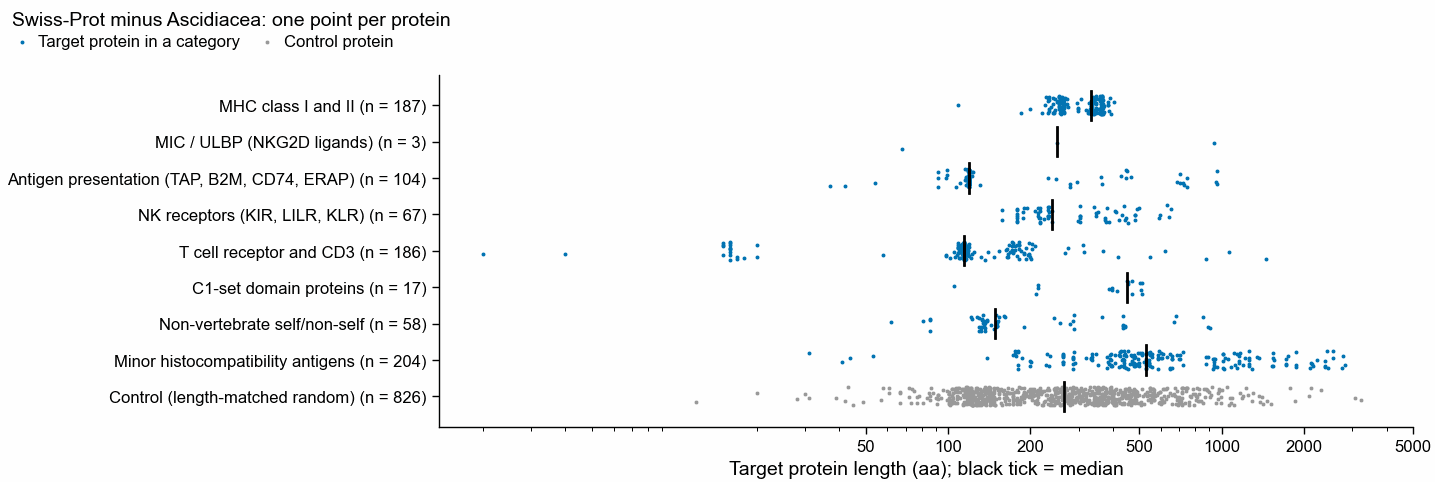

In [3]:
targets = bmu.load_targets(
    DATA
)  # length_decile: the control's length deciles, for section 3
category_table = (
    targets.group_by("category")
    .agg(
        n_targets=pl.len(),
        median_length_aa=pl.col("length").median(),
        q25_length_aa=pl.col("length").quantile(0.25),
        q75_length_aa=pl.col("length").quantile(0.75),
    )
    .with_columns(
        order=pl.col("category").map_elements(ORDER.index, return_dtype=pl.Int64)
    )
    .sort("order")
    .drop("order")
)
print(category_table)

fig, ax = pf.figure(pf.TWO_COLUMN_MM, 62)
rng = np.random.default_rng(0)
for i, cat in enumerate(ORDER):
    lengths = targets.filter(pl.col("category") == cat)["length"].to_numpy()
    y = i + rng.uniform(-0.25, 0.25, len(lengths))
    ax.scatter(
        lengths,
        y,
        s=2,
        color=pf.GREY if cat == "control" else pf.OKABE_ITO["blue"],
        linewidths=0,
        label="Control protein" if cat == "control" else "Target protein in a category",
    )
    ax.plot([np.median(lengths)] * 2, [i - 0.4, i + 0.4], color="black", lw=1)
ax.set_yticks(
    range(len(ORDER)),
    [
        f"{CATEGORY_NAME[c]} (n = {targets.filter(pl.col('category') == c).height})"
        for c in ORDER
    ],
)
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xticks(
    [50, 100, 200, 500, 1000, 2000, 5000],
    ["50", "100", "200", "500", "1000", "2000", "5000"],
)
ax.set_xlabel("Target protein length (aa); black tick = median")
legend_on_top(fig, "Swiss-Prot minus Ascidiacea: one point per protein")
pf.save(fig, FIG / f"281_target_lengths_by_category_{SOURCE}")

## 2. Regions kept after dropping low-complexity, helix and wrong-target rows

Notebook 279 found that kmerseek's regions on dark proteins lean towards low-complexity
sequence (a stretch made of few residue types) and transmembrane helices (a run of
hydrophobic residues that crosses the membrane). Both match unrelated proteins easily. A
region is dropped when at least half of its residues, on the Botryllus protein or on the
target, sit in either kind of stretch (SEG first pass for low complexity; Kyte-Doolittle
19-residue windows for helices; see `tools/dark-regions`).

A region is also dropped when its target residues are not in the named target at all.
kmerseek 0.4.0 merges index entries with the same k-mer set and then reports the second
name with the first entry's coordinates ([kmerseek PR 141](https://github.com/seanome/kmerseek/pull/141)),
so the target name of such a row is wrong.

The table counts regions with E < the cutoff, by the reason they were dropped (a region
can have more than one reason; *kept* is the rest).

870_727 regions with E < 10 from 22_585 Botryllus proteins, 174 alphabet and k-size pairs, on 1_462 of 1_652 target and control proteins

Regions with E < 1:
┌────────────────────────────┬─────────┬────────────────┬───────┬──────────────┬───────┬────────────┐
│ category                   ┆ regions ┆ low_complexity ┆ helix ┆ wrong_target ┆ kept  ┆ kept_share │
│ ---                        ┆ ---     ┆ ---            ┆ ---   ┆ ---          ┆ ---   ┆ ---        │
│ str                        ┆ u32     ┆ u32            ┆ u32   ┆ u32          ┆ u32   ┆ f64        │
╞════════════════════════════╪═════════╪════════════════╪═══════╪══════════════╪═══════╪════════════╡
│ mhc                        ┆ 521     ┆ 351            ┆ 313   ┆ 0            ┆ 146   ┆ 0.28023    │
│ mhc_like_nkg2d_ligand      ┆ 25      ┆ 0              ┆ 0     ┆ 0            ┆ 25    ┆ 1.0        │
│ antigen_presentation       ┆ 6889    ┆ 201            ┆ 26    ┆ 0            ┆ 6672  ┆ 0.968501   │
│ nk_receptor             

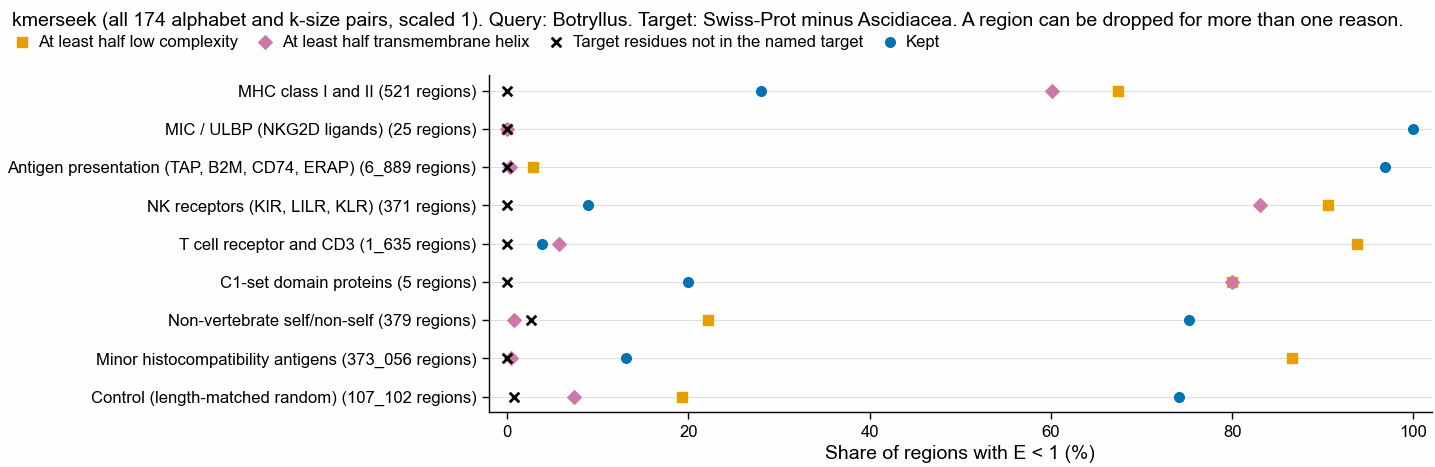

In [4]:
regions_all = bmu.load_regions(DATA, targets, MAX_BIASED_SHARE)
print(
    f"{regions_all.height:_} regions with E < 10 from {regions_all['query_name'].n_unique():_} Botryllus proteins, "
    f"{regions_all.select(pl.struct('alphabet', 'ksize').n_unique()).item()} alphabet and k-size pairs, "
    f"on {regions_all['target_name'].n_unique():_} of {targets.height:_} target and control proteins"
)


below = regions_all.filter(pl.col("region_evalue") < E_CUTOFF)
filter_table = (
    below.group_by("category")
    .agg(
        regions=pl.len(),
        low_complexity=pl.col("low_complexity").sum(),
        helix=pl.col("helix").sum(),
        wrong_target=pl.col("wrong_target").sum(),
        kept=pl.col("kept").sum(),
    )
    .with_columns(
        kept_share=pl.col("kept") / pl.col("regions"),
        order=pl.col("category").map_elements(ORDER.index, return_dtype=pl.Int64),
    )
    .sort("order")
    .drop("order")
)
print(f"\nRegions with E < {E_CUTOFF}:")
print(filter_table)

fig, ax = pf.figure(pf.TWO_COLUMN_MM, 60)
reasons = [
    ("low_complexity", "At least half low complexity", pf.OKABE_ITO["orange"], "s"),
    ("helix", "At least half transmembrane helix", pf.OKABE_ITO["reddish_purple"], "D"),
    (
        "wrong_target",
        "Target residues not in the named target",
        pf.OKABE_ITO["black"],
        "x",
    ),
    ("kept", "Kept", pf.OKABE_ITO["blue"], "o"),
]
cats = filter_table["category"].to_list()
for col, label, color, marker in reasons:
    share = (filter_table[col] / filter_table["regions"]).to_numpy()
    ax.scatter(
        share * 100, range(len(cats)), color=color, marker=marker, s=12, label=label
    )
ax.set_yticks(
    range(len(cats)),
    [
        f"{CATEGORY_NAME[c]} ({n:_} regions)"
        for c, n in zip(cats, filter_table["regions"])
    ],
)
ax.invert_yaxis()
ax.grid(axis="y")
ax.set_xlim(-2, 102)
ax.set_xlabel(f"Share of regions with E < {E_CUTOFF} (%)")
legend_on_top(
    fig,
    f"kmerseek (all 174 alphabet and k-size pairs, scaled 1). Query: Botryllus. "
    "Target: Swiss-Prot minus Ascidiacea. A region can be dropped for more than one reason.",
)
pf.save(fig, FIG / f"281_regions_dropped_lowcomplexity_helix_wrong_target_{SOURCE}")

regions = regions_all.filter(pl.col("kept"))

## 3. Share of each category's targets that kmerseek and each tool reach, against the length-matched control

For kmerseek and for each tool, the share of a category's targets with at least one link
(kmerseek) or hit (tool) from any Botryllus protein with E < the cutoff. *Expected* is the
length-matched control share. *Fold* is observed / expected: 1 means the category is
reached as often as random proteins of the same length; above 1 is more often (a sign of
real homologs in Botryllus); below 1 is less often.

**How to read the figure.** Panel a gives the raw shares, with the control in the top row.
Panel b gives the fold: points right of the dashed line at 1 are categories each tool
reaches more often than random proteins of their length. A category Botryllus has real
homologs of should sit right of 1 for the tools as well as for kmerseek.

In [5]:
tool_hits_all = bmu.load_tool_hits(DATA, targets)
print(
    "Tool hits on target and control proteins, E <= 10:",
    dict(tool_hits_all.group_by("tool").len().iter_rows()),
)


def reached_targets(cutoff):
    # One row per (method, target) reached at E < cutoff.
    k = (
        regions.filter(pl.col("region_evalue") < cutoff)
        .select("target_name")
        .unique()
        .with_columns(method=pl.lit("kmerseek"))
    )
    t = (
        tool_hits_all.filter(pl.col("evalue") < cutoff)
        .select(pl.col("tool").alias("method"), "target_name")
        .unique()
    )
    return pl.concat([k.select("method", "target_name"), t])


def compare_with_control(reached, label_col="method"):
    # Observed and length-matched expected share per category and method, with a one-sided
    # binomial test (observed > expected) and Bonferroni correction over the categories.
    flagged = targets.join(
        reached.with_columns(hit=pl.lit(1)),
        left_on="accession",
        right_on="target_name",
        how="inner",
    )
    rows = []
    for method in reached[label_col].unique().sort():
        hit = set(flagged.filter(pl.col(label_col) == method)["accession"])
        tm = targets.with_columns(hit=pl.col("accession").is_in(list(hit)))
        control_rate = (
            tm.filter(pl.col("category") == "control")
            .group_by("length_decile")
            .agg(rate=pl.col("hit").mean())
        )
        tm = tm.join(control_rate, on="length_decile")
        for cat in ORDER:
            c = tm.filter(pl.col("category") == cat)
            n, k = c.height, int(c["hit"].sum())
            expected = float(c["rate"].mean())
            p = (
                binomtest(k, n, expected, alternative="greater").pvalue
                if 0 < expected < 1
                else float("nan")
            )
            rows.append(
                dict(
                    method=method,
                    category=cat,
                    n_targets=n,
                    n_reached=k,
                    share=k / n,
                    expected_share=expected,
                    fold=(k / n) / expected if expected > 0 else float("nan"),
                    p_one_sided=p,
                )
            )
    out = pl.DataFrame(rows).with_columns(
        p_bonferroni=pl.when(pl.col("category") == "control")
        .then(None)
        .otherwise((pl.col("p_one_sided") * len(CATEGORIES)).clip(upper_bound=1.0))
    )
    return (
        out.with_columns(
            order=pl.col("category").map_elements(ORDER.index, return_dtype=pl.Int64)
        )
        .sort("method", "order")
        .drop("order")
    )


reach = pl.concat(
    [
        compare_with_control(reached_targets(c)).with_columns(e_cutoff=pl.lit(float(c)))
        for c in (E_CUTOFF, E_CUTOFF_STRICT, E_CUTOFF_LOOSE)
    ]
)
reach.write_csv(TABLES / f"281_targets_reached_by_category_vs_control_{SOURCE}.csv")
print(
    reach.select(
        "e_cutoff",
        "method",
        "category",
        "n_targets",
        "n_reached",
        "share",
        "expected_share",
        "fold",
        "p_bonferroni",
    )
)

Tool hits on target and control proteins, E <= 10: {'phmmer': 30717, 'jackhmmer': 143093, 'mmseqs2': 15045}
┌──────────┬───────────┬────────────────────────────┬───────────┬───────────┬──────────┬────────────────┬──────────┬──────────────┐
│ e_cutoff ┆ method    ┆ category                   ┆ n_targets ┆ n_reached ┆ share    ┆ expected_share ┆ fold     ┆ p_bonferroni │
│ ---      ┆ ---       ┆ ---                        ┆ ---       ┆ ---       ┆ ---      ┆ ---            ┆ ---      ┆ ---          │
│ f64      ┆ str       ┆ str                        ┆ i64       ┆ i64       ┆ f64      ┆ f64            ┆ f64      ┆ f64          │
╞══════════╪═══════════╪════════════════════════════╪═══════════╪═══════════╪══════════╪════════════════╪══════════╪══════════════╡
│ 1.0      ┆ jackhmmer ┆ mhc                        ┆ 187       ┆ 170       ┆ 0.909091 ┆ 0.767931       ┆ 1.183819 ┆ 0.000003     │
│ 1.0      ┆ jackhmmer ┆ mhc_like_nkg2d_ligand      ┆ 3         ┆ 1         ┆ 0.333333 ┆ 0.729743   

┌───────────┬────────────────────────────┬───────────┬───────────┬──────────┬────────────────┬──────────┬──────────────┐
│ method    ┆ category                   ┆ n_targets ┆ n_reached ┆ share    ┆ expected_share ┆ fold     ┆ p_bonferroni │
│ ---       ┆ ---                        ┆ ---       ┆ ---       ┆ ---      ┆ ---            ┆ ---      ┆ ---          │
│ str       ┆ str                        ┆ i64       ┆ i64       ┆ f64      ┆ f64            ┆ f64      ┆ f64          │
╞═══════════╪════════════════════════════╪═══════════╪═══════════╪══════════╪════════════════╪══════════╪══════════════╡
│ jackhmmer ┆ mhc                        ┆ 187       ┆ 170       ┆ 0.909091 ┆ 0.767931       ┆ 1.183819 ┆ 0.000003     │
│ jackhmmer ┆ mhc_like_nkg2d_ligand      ┆ 3         ┆ 1         ┆ 0.333333 ┆ 0.729743       ┆ 0.456782 ┆ 1.0          │
│ jackhmmer ┆ antigen_presentation       ┆ 104       ┆ 98        ┆ 0.942308 ┆ 0.723138       ┆ 1.303082 ┆ 1.0323e-7    │
│ jackhmmer ┆ nk_receptor       

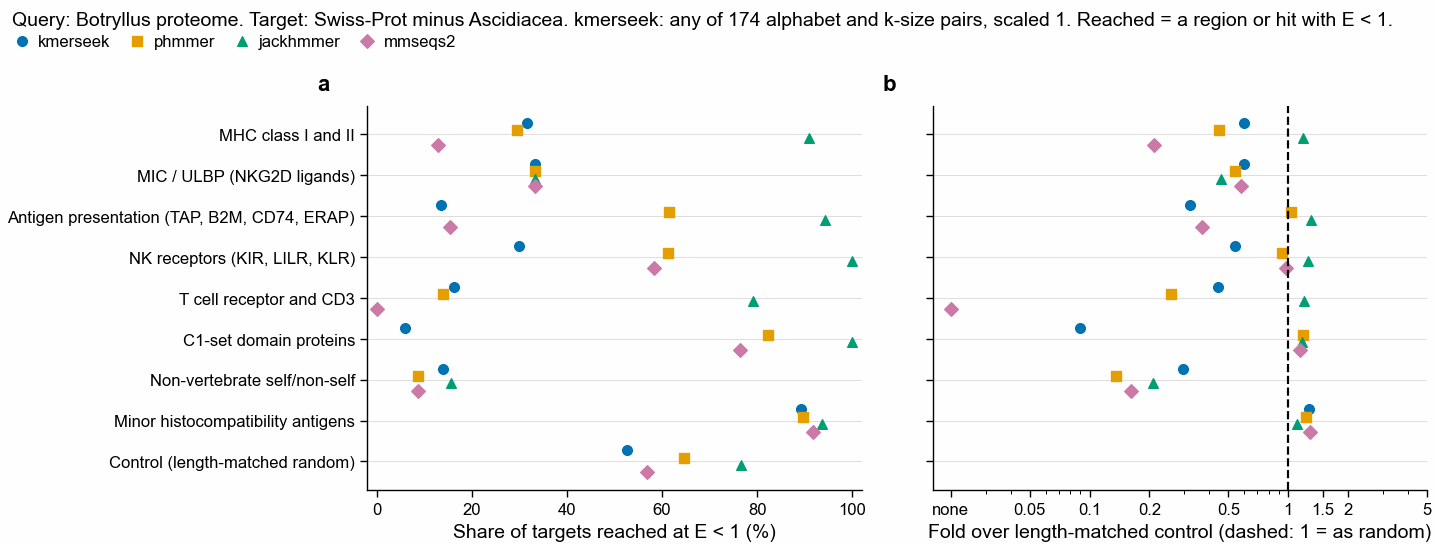

In [6]:
def category_dot_panels(table, value_methods, title, fname, xlabel_share):
    fig, (ax_a, ax_b) = pf.figure(pf.TWO_COLUMN_MM, 70, ncols=2, sharey=True)
    offsets = np.linspace(-0.27, 0.27, len(value_methods))
    for off, method in zip(offsets, value_methods):
        t = table.filter(pl.col("method") == method)
        y = np.array([ORDER.index(c) for c in t["category"]]) + off
        style = TOOL_STYLE[method.split(" ")[0]]
        ax_a.scatter(t["share"] * 100, y, s=12, label=method, **style)
        tb = t.filter(pl.col("category") != "control")
        yb = np.array([ORDER.index(c) for c in tb["category"]]) + off
        fold = tb["fold"].to_numpy()
        ax_b.scatter(np.clip(fold, 0.02, None), yb, s=12, **style)
    ax_a.set_yticks(range(len(ORDER)), [CATEGORY_NAME[c] for c in ORDER])
    ax_a.invert_yaxis()
    for ax in (ax_a, ax_b):
        ax.grid(axis="y")
    ax_a.set_xlim(-2, 102)
    ax_a.set_xlabel(xlabel_share)
    ax_b.axvline(1, color="black", ls="--", lw=0.8)
    ax_b.set_xscale("log")
    ax_b.set_xticks(*FOLD_TICKS)
    ax_b.set_xlabel("Fold over length-matched control (dashed: 1 = as random)")
    pf.panel_label(ax_a, "a")
    pf.panel_label(ax_b, "b")
    legend_on_top(fig, title)
    pf.save(fig, FIG / fname)


t1 = reach.filter(pl.col("e_cutoff") == E_CUTOFF)
print(
    t1.select(
        "method",
        "category",
        "n_targets",
        "n_reached",
        "share",
        "expected_share",
        "fold",
        "p_bonferroni",
    )
)
category_dot_panels(
    t1,
    ["kmerseek", "phmmer", "jackhmmer", "mmseqs2"],
    f"Query: Botryllus proteome. Target: Swiss-Prot minus Ascidiacea. kmerseek: any of 174 alphabet and k-size pairs, "
    f"scaled 1. Reached = a region or hit with E < {E_CUTOFF}.",
    f"281_targets_reached_by_category_kmerseek_phmmer_jackhmmer_mmseqs2_E{E_CUTOFF}_{SOURCE}",
    f"Share of targets reached at E < {E_CUTOFF} (%)",
)

## 4. kmerseek-only links: the decision

Each kmerseek link is split by whether any tool reports a hit between the same two proteins
(at any E-value up to 10). The test of the decision rule is on the share of targets with at
least one kmerseek-only link, against the same share among length-matched control
proteins. The control proteins collect kmerseek-only links by the same route (174 alphabet
and k-size pairs, the same Botryllus proteome), so the comparison asks whether these
categories collect *more* of them than random proteins.

**How to read the figure.** Panel a: the share of each category's targets reached
kmerseek-only (blue) and the share expected from the control at the same lengths (grey
bar). Panel b: the fold. A category passes the rule when its point is right of the dotted
line at 1.5 and its Bonferroni p-value (printed in the table) is below 0.05.

┌──────────┬────────────────────────────┬───────────┬───────────┬──────────┬────────────────┬──────────┬──────────────┬────────┬───────┬─────────────────────┬──────────────────────────────────┐
│ e_cutoff ┆ category                   ┆ n_targets ┆ n_reached ┆ share    ┆ expected_share ┆ fold     ┆ p_bonferroni ┆ passes ┆ links ┆ links_kmerseek_only ┆ botryllus_proteins_kmerseek_only │
│ ---      ┆ ---                        ┆ ---       ┆ ---       ┆ ---      ┆ ---            ┆ ---      ┆ ---          ┆ ---    ┆ ---   ┆ ---                 ┆ ---                              │
│ f64      ┆ str                        ┆ i64       ┆ i64       ┆ f64      ┆ f64            ┆ f64      ┆ f64          ┆ bool   ┆ u32   ┆ u32                 ┆ u32                              │
╞══════════╪════════════════════════════╪═══════════╪═══════════╪══════════╪════════════════╪══════════╪══════════════╪════════╪═══════╪═════════════════════╪══════════════════════════════════╡
│ 1.0      ┆ mhc              

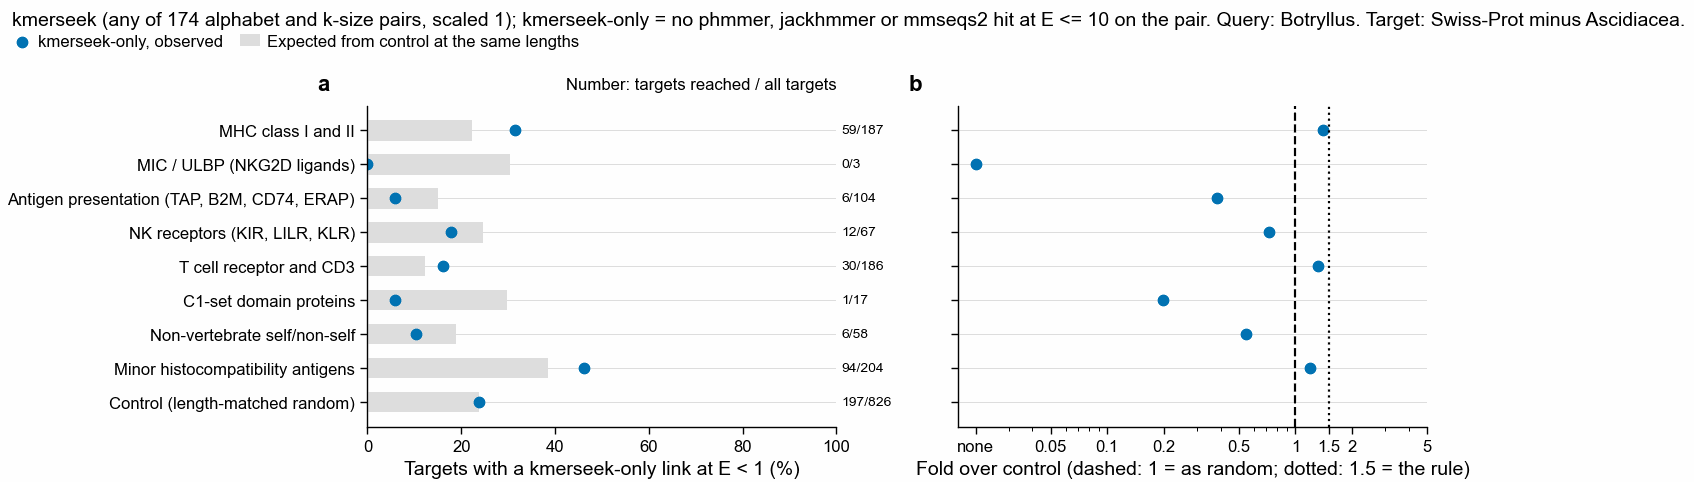

In [7]:
tool_pairs = (
    tool_hits_all.filter(pl.col("evalue") <= TOOL_MISS_E)
    .select("query_name", "target_name")
    .unique()
)


def links_at(cutoff):
    return bmu.links_at(regions, tool_pairs, cutoff)


decision_rows = []
for cutoff in (E_CUTOFF, E_CUTOFF_STRICT, E_CUTOFF_LOOSE):
    lk = links_at(cutoff)
    only = (
        lk.filter(~pl.col("tool_found"))
        .select("target_name")
        .unique()
        .with_columns(method=pl.lit("kmerseek-only"))
    )
    cmp = compare_with_control(only).with_columns(e_cutoff=pl.lit(float(cutoff)))
    counts = lk.group_by("category").agg(
        links=pl.len(),
        links_kmerseek_only=(~pl.col("tool_found")).sum(),
        botryllus_proteins_kmerseek_only=pl.col("query_name")
        .filter(~pl.col("tool_found"))
        .n_unique(),
    )
    decision_rows.append(
        cmp.join(counts, on="category", how="left").with_columns(
            passes=(pl.col("fold") >= MIN_FOLD_OVER_CONTROL)
            & (pl.col("p_bonferroni") < ALPHA)
        )
    )
decision = pl.concat(decision_rows)
decision.write_csv(
    TABLES / f"281_kmerseek_only_targets_by_category_vs_control_{SOURCE}.csv"
)
print(
    decision.select(
        "e_cutoff",
        "category",
        "n_targets",
        "n_reached",
        "share",
        "expected_share",
        "fold",
        "p_bonferroni",
        "passes",
        "links",
        "links_kmerseek_only",
        "botryllus_proteins_kmerseek_only",
    )
)

d1 = decision.filter(pl.col("e_cutoff") == E_CUTOFF)
passing = d1.filter(pl.col("passes"))["category"].to_list()
print(
    f"\nCategories passing the rule at E < {E_CUTOFF}: {passing if passing else 'none'}"
)


def draw_decision(d, cutoff):
    fig, (ax_a, ax_b) = pf.figure(pf.TWO_COLUMN_MM, 62, ncols=2, sharey=True)
    y = np.array([ORDER.index(c) for c in d["category"]])
    ax_a.barh(
        y,
        d["expected_share"] * 100,
        height=0.6,
        color="#DDDDDD",
        label="Expected from control at the same lengths",
    )
    ax_a.scatter(
        d["share"] * 100,
        y,
        s=14,
        label="kmerseek-only, observed",
        **TOOL_STYLE["kmerseek"],
    )
    db = d.filter(pl.col("category") != "control")
    yb = np.array([ORDER.index(c) for c in db["category"]])
    ax_b.scatter(
        np.clip(db["fold"].to_numpy(), 0.02, None), yb, s=14, **TOOL_STYLE["kmerseek"]
    )
    ax_b.axvline(1, color="black", ls="--", lw=0.8)
    ax_b.axvline(MIN_FOLD_OVER_CONTROL, color="black", ls=":", lw=0.8)
    for yy, n, k in zip(y, d["n_targets"], d["n_reached"]):
        ax_a.annotate(
            f"{k}/{n}", (101, yy), va="center", fontsize=5, annotation_clip=False
        )
    ax_a.set_yticks(range(len(ORDER)), [CATEGORY_NAME[c] for c in ORDER])
    ax_a.invert_yaxis()
    for ax in (ax_a, ax_b):
        ax.grid(axis="y")
    ax_a.set_xlim(0, 100)
    ax_a.set_xlabel(f"Targets with a kmerseek-only link at E < {cutoff} (%)")
    ax_a.set_title("Number: targets reached / all targets", loc="right", fontsize=6)
    ax_b.set_xscale("log")
    ax_b.set_xticks(*FOLD_TICKS)
    ax_b.set_xlabel("Fold over control (dashed: 1 = as random; dotted: 1.5 = the rule)")
    pf.panel_label(ax_a, "a")
    pf.panel_label(ax_b, "b")
    legend_on_top(
        fig,
        "kmerseek (any of 174 alphabet and k-size pairs, scaled 1); kmerseek-only = no phmmer, jackhmmer or "
        "mmseqs2 hit at E <= 10 on the pair. Query: Botryllus. Target: Swiss-Prot minus Ascidiacea.",
    )
    pf.save(
        fig,
        FIG / f"281_kmerseek_only_targets_by_category_vs_control_E{cutoff}_{SOURCE}",
    )


draw_decision(d1, E_CUTOFF)

## 5. Do kmerseek-only links look like the links the tools also find?

Two checks, per link, that do not depend on the E-value:

* **Identity above chance.** Most kmerseek regions are gapless, so the two residue strings
  line up position by position. A region chained from seeds at different offsets (an
  insertion or deletion between them) has strings of different lengths; it gets no identity
  and is counted separately in the table. *Identity* is the share of positions with the same amino acid.
  *Chance identity* is what two strings with these two compositions would share at random
  (the sum over the 20 amino acids of the product of their frequencies in each string).
  The figure shows identity minus chance identity, in percentage points: 0 means no more
  matches than random; real homologs at twilight-zone identity (20-30%) sit about 15-25
  points above.
* **The same in the alphabet's letters.** kmerseek compares residues in the reduced
  alphabet of the region (for gbmr4: G, P, CFHILMVWY and ADEKNQRST), so a region can match
  in letters while the amino acids do not. *Letter identity* is the share of positions with
  the same letter, with its chance value from the letter compositions. Each alphabet's
  letter for each amino acid is read off the run's own output, where kmerseek writes the
  target residues in letters.
* **How many alphabets find the link.** A region a real homolog leaves behind usually shows
  up in several reduced alphabets; a pattern match in one alphabet's letters does not have
  to.

Groups: links also found by a tool, and kmerseek-only links, each for the categories
(all eight together) and for the control.

Links at E < 1 (best region per link):
┌────────────┬────────────┬───────┬────────────────────────────┬─────────────────────┬──────────────────────────────┬────────────────────────────────────┬─────────────────────────┬──────────────────┬────────────────────┐
│ group      ┆ tool_found ┆ links ┆ lengths_differ_no_identity ┆ median_identity_pct ┆ median_identity_above_chance ┆ median_letter_identity_above_chanc ┆ share_above_chance_by_5 ┆ median_alphabets ┆ share_one_alphabet │
│ ---        ┆ ---        ┆ ---   ┆ ---                        ┆ ---                 ┆ ---                          ┆ e                                  ┆ ---                     ┆ ---              ┆ ---                │
│ str        ┆ bool       ┆ u32   ┆ u32                        ┆ f64                 ┆ f64                          ┆ ---                                ┆ f64                     ┆ f64              ┆ f64                │
│            ┆            ┆       ┆                            ┆             

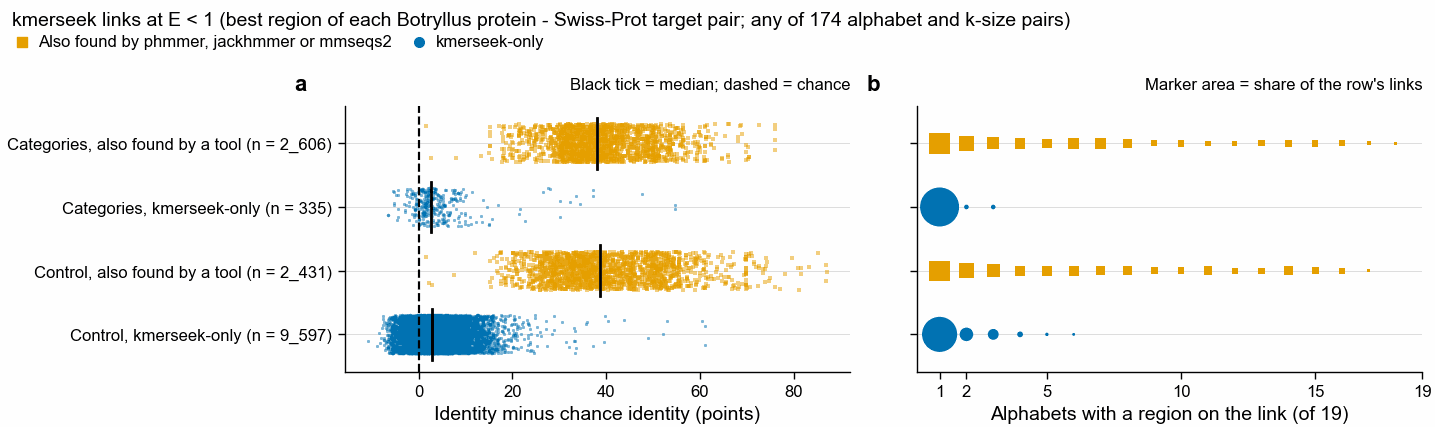

In [8]:
letter_maps = bmu.alphabet_letter_maps(
    regions_all
)  # read off the run's own encoded target residues


def with_identity(lk):
    return bmu.with_identity(lk, letter_maps)


def identity_summary(lk):
    return (
        lk.group_by("group", "tool_found")
        .agg(
            links=pl.len(),
            lengths_differ_no_identity=pl.col("identity").is_null().sum(),
            median_identity_pct=pl.col("identity").median() * 100,
            median_identity_above_chance=pl.col("identity_above_chance").median(),
            median_letter_identity_above_chance=pl.col(
                "letter_identity_above_chance"
            ).median(),
            share_above_chance_by_5=(pl.col("identity_above_chance") >= 5).mean(),
            median_alphabets=pl.col("n_alphabets").median(),
            share_one_alphabet=(pl.col("n_alphabets") == 1).mean(),
        )
        .sort("group", "tool_found", descending=[False, True])
    )


links = with_identity(links_at(E_CUTOFF))
GROUPS = [
    ("categories", True, "Categories, also found by a tool"),
    ("categories", False, "Categories, kmerseek-only"),
    ("control", True, "Control, also found by a tool"),
    ("control", False, "Control, kmerseek-only"),
]
summary5 = identity_summary(links)
print(f"Links at E < {E_CUTOFF} (best region per link):")
print(summary5)

fig, (ax_a, ax_b) = pf.figure(pf.TWO_COLUMN_MM, 55, ncols=2, sharey=True)
rng = np.random.default_rng(0)
for i, (g, found, label) in enumerate(GROUPS):
    s = links.filter((pl.col("group") == g) & (pl.col("tool_found") == found))
    color = pf.OKABE_ITO["orange"] if found else pf.OKABE_ITO["blue"]
    marker = "s" if found else "o"
    v = s["identity_above_chance"].drop_nulls().to_numpy()
    ax_a.scatter(
        v,
        i + rng.uniform(-0.3, 0.3, len(v)),
        s=1.5,
        color=color,
        marker=marker,
        linewidths=0,
        alpha=0.5,
    )
    ax_a.plot([np.median(v)] * 2, [i - 0.4, i + 0.4], color="black", lw=1)
    counts = s.group_by("n_alphabets").len().sort("n_alphabets")
    share = counts["len"].to_numpy() / s.height * 100
    ax_b.scatter(
        counts["n_alphabets"],
        [i] * counts.height,
        s=share * 2 + 1,
        color=color,
        marker=marker,
        linewidths=0,
    )
ax_a.set_yticks(
    range(len(GROUPS)),
    [
        f"{lab} (n = {links.filter((pl.col('group') == g) & (pl.col('tool_found') == f)).height:_})"
        for g, f, lab in GROUPS
    ],
)
ax_a.invert_yaxis()
ax_a.axvline(0, color="black", ls="--", lw=0.8)
ax_a.set_xlabel("Identity minus chance identity (points)")
ax_a.set_title("Black tick = median; dashed = chance", loc="right", fontsize=6)
ax_b.set_xlabel("Alphabets with a region on the link (of 19)")
ax_b.set_title("Marker area = share of the row's links", loc="right", fontsize=6)
ax_b.set_xticks([1, 2, 5, 10, 15, 19])
for ax in (ax_a, ax_b):
    ax.grid(axis="y")
ax_a.scatter(
    [],
    [],
    color=pf.OKABE_ITO["orange"],
    marker="s",
    s=12,
    label="Also found by phmmer, jackhmmer or mmseqs2",
)
ax_a.scatter(
    [], [], color=pf.OKABE_ITO["blue"], marker="o", s=12, label="kmerseek-only"
)
pf.panel_label(ax_a, "a")
pf.panel_label(ax_b, "b")
legend_on_top(
    fig,
    f"kmerseek links at E < {E_CUTOFF} (best region of each Botryllus protein - Swiss-Prot target pair; "
    "any of 174 alphabet and k-size pairs)",
)
pf.save(fig, FIG / f"281_link_identity_above_chance_and_alphabets_E{E_CUTOFF}_{SOURCE}")

## 6. The same test at E < 10

E < 10 keeps every region the extraction kept. At this cutoff a link needs only a region
that chance alone would produce up to 10 times per search, so many more control proteins
get one too; the length-matched control still sets the bar. The decision rule was written
for E < 1; this section shows whether a looser cutoff would have changed it. Tool hits
count up to E = 10 at every cutoff, so a kmerseek-only link means the same thing here.

**A limit of the fold test at this cutoff.** A share cannot pass 100%, so the largest fold a
category can reach is 1 / expected share. Where the control already reaches more than two
thirds of the proteins at that length, 1.5-fold is out of reach whatever Botryllus holds
(for MHC, expected 88%, the most is 1.13). At E < 10 the identity check below is the more
informative one: do the kmerseek-only links to the categories match better than those to
the control?

┌────────────────────────────┬───────────┬───────────┬──────────┬────────────────┬──────────┬──────────────┬────────┬───────┬─────────────────────┬──────────────────────────────────┐
│ category                   ┆ n_targets ┆ n_reached ┆ share    ┆ expected_share ┆ fold     ┆ p_bonferroni ┆ passes ┆ links ┆ links_kmerseek_only ┆ botryllus_proteins_kmerseek_only │
│ ---                        ┆ ---       ┆ ---       ┆ ---      ┆ ---            ┆ ---      ┆ ---          ┆ ---    ┆ ---   ┆ ---                 ┆ ---                              │
│ str                        ┆ i64       ┆ i64       ┆ f64      ┆ f64            ┆ f64      ┆ f64          ┆ bool   ┆ u32   ┆ u32                 ┆ u32                              │
╞════════════════════════════╪═══════════╪═══════════╪══════════╪════════════════╪══════════╪══════════════╪════════╪═══════╪═════════════════════╪══════════════════════════════════╡
│ mhc                        ┆ 187       ┆ 184       ┆ 0.983957 ┆ 0.884612       ┆ 1.


Links at E < 10 (best region per link):
┌────────────┬────────────┬───────┬────────────────────────────┬─────────────────────┬──────────────────────────────┬────────────────────────────────────┬─────────────────────────┬──────────────────┬────────────────────┐
│ group      ┆ tool_found ┆ links ┆ lengths_differ_no_identity ┆ median_identity_pct ┆ median_identity_above_chance ┆ median_letter_identity_above_chanc ┆ share_above_chance_by_5 ┆ median_alphabets ┆ share_one_alphabet │
│ ---        ┆ ---        ┆ ---   ┆ ---                        ┆ ---                 ┆ ---                          ┆ e                                  ┆ ---                     ┆ ---              ┆ ---                │
│ str        ┆ bool       ┆ u32   ┆ u32                        ┆ f64                 ┆ f64                          ┆ ---                                ┆ f64                     ┆ f64              ┆ f64                │
│            ┆            ┆       ┆                            ┆           

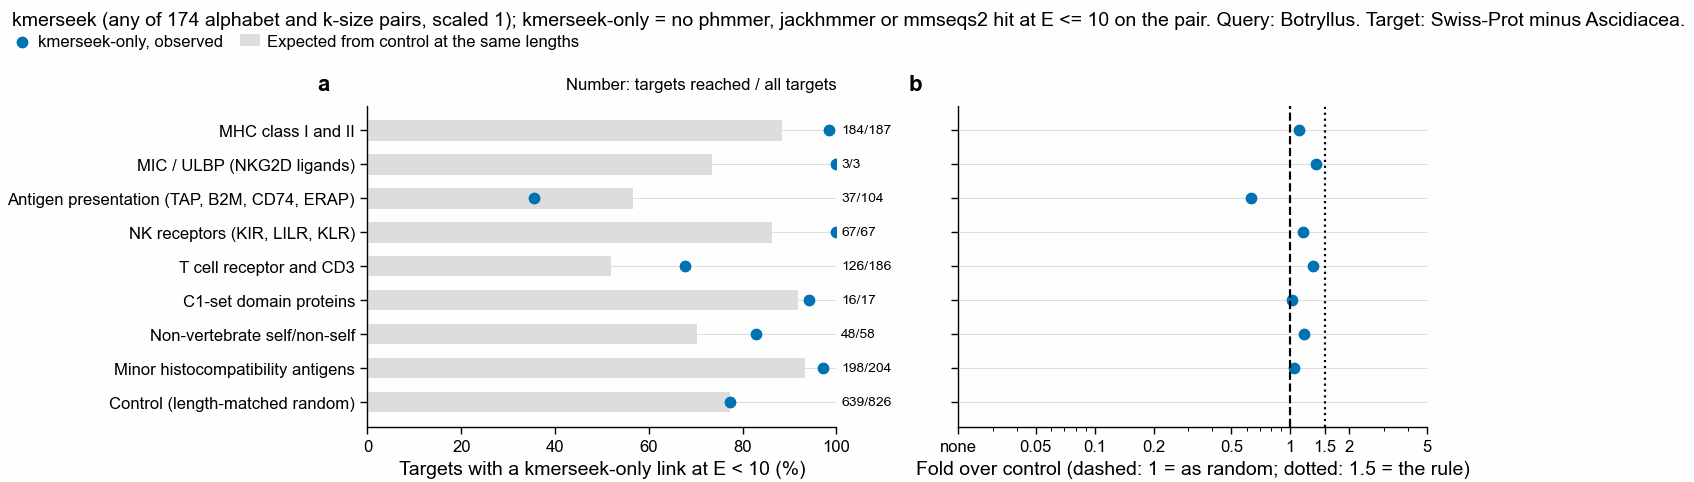

In [9]:
d10 = decision.filter(pl.col("e_cutoff") == E_CUTOFF_LOOSE)
print(
    d10.select(
        "category",
        "n_targets",
        "n_reached",
        "share",
        "expected_share",
        "fold",
        "p_bonferroni",
        "passes",
        "links",
        "links_kmerseek_only",
        "botryllus_proteins_kmerseek_only",
    )
)
passing10 = d10.filter(pl.col("passes"))["category"].to_list()
print(
    f"\nCategories passing the rule at E < {E_CUTOFF_LOOSE}: {passing10 if passing10 else 'none'}"
)
links10 = with_identity(links_at(E_CUTOFF_LOOSE))
print(f"\nLinks at E < {E_CUTOFF_LOOSE} (best region per link):")
print(identity_summary(links10))
draw_decision(d10, E_CUTOFF_LOOSE)

## 7. Which alphabets give the kmerseek-only links

Alphabets are grouped by size (number of residue classes): 2-3, 4-8, 12-18, and the
20-letter protein alphabet. The share is of all kmerseek-only links (best region per link)
in the eight categories, and the same for the control.

┌─────────┬──────────────────────────┬────────────┬─────────┐
│ classes ┆ alphabet                 ┆ categories ┆ control │
│ ---     ┆ ---                      ┆ ---        ┆ ---     │
│ i64     ┆ str                      ┆ u32        ┆ u32     │
╞═════════╪══════════════════════════╪════════════╪═════════╡
│ 2       ┆ hp_kyte_doolittle2       ┆ 9          ┆ 785     │
│ 2       ┆ hp_lehninger2            ┆ 15         ┆ 393     │
│ 2       ┆ hp_lehninger_c_nonpolar2 ┆ 10         ┆ 486     │
│ 2       ┆ hp_pbotc_1st_ed2         ┆ 8          ┆ 960     │
│ 2       ┆ hp_thomas_dill2          ┆ 17         ┆ 673     │
│ 2       ┆ hp_thomas_dill_no_c2     ┆ 5          ┆ 359     │
│ 3       ┆ hp_lehninger_hpc3        ┆ 119        ┆ 1871    │
│ 4       ┆ gbmr4                    ┆ 125        ┆ 3421    │
│ 4       ┆ polarity4                ┆ 5          ┆ 422     │
│ 5       ┆ wwmj5                    ┆ 6          ┆ 69      │
│ 6       ┆ dayhoff6                 ┆ 0          ┆ 98      │
│ 7     

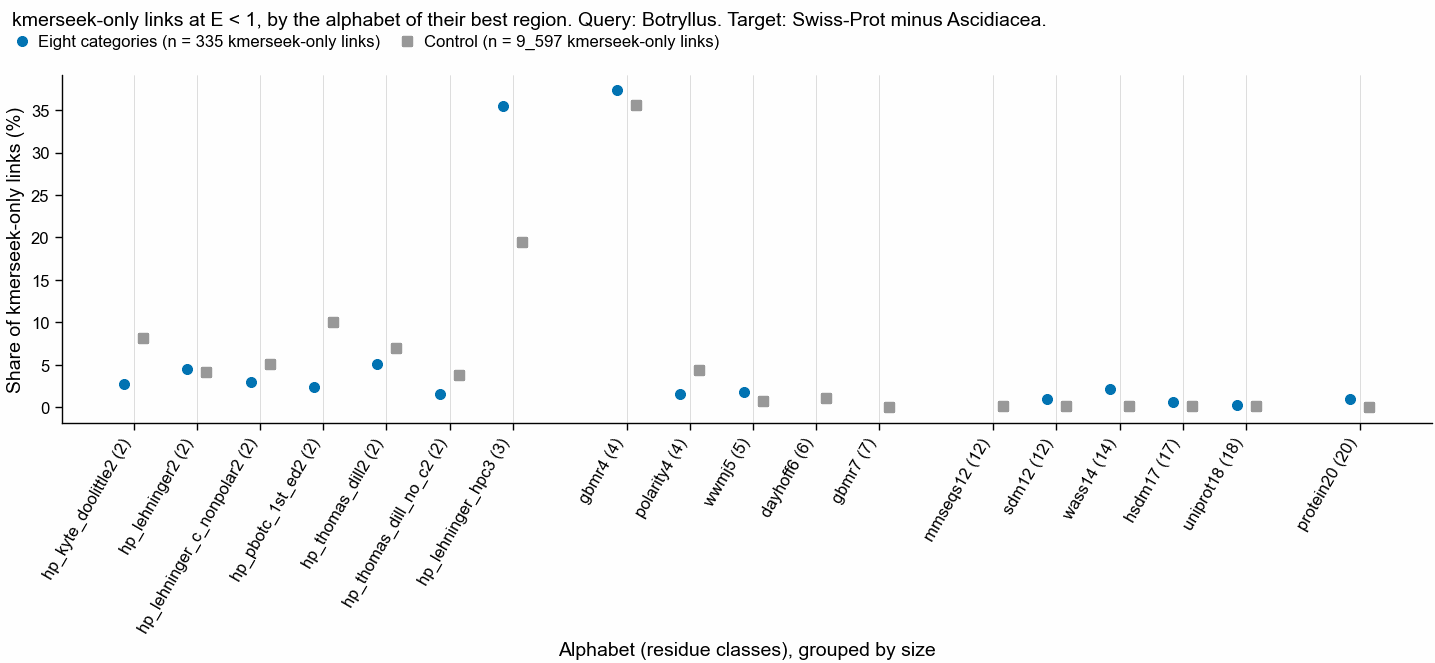

In [10]:
def classes(alphabet: str) -> int:
    # Residue classes are the trailing number of the alphabet's name (hp_lehninger_hpc3 -> 3).
    digits = ""
    for ch in reversed(alphabet):
        if not ch.isdigit():
            break
        digits = ch + digits
    return int(digits)


only = links.filter(~pl.col("tool_found"))
alph = (
    only.group_by("group", "alphabet")
    .len()
    .with_columns(
        share=pl.col("len") / pl.col("len").sum().over("group"),
        classes=pl.col("alphabet").map_elements(classes, return_dtype=pl.Int64),
    )
    .sort("classes", "alphabet")
)
print(
    alph.pivot(on="group", index=["classes", "alphabet"], values="len")
    .fill_null(0)
    .sort("classes", "alphabet")
)

alphabets = alph.select("alphabet", "classes").unique().sort("classes", "alphabet")
size_group = lambda c: 0 if c <= 3 else 1 if c <= 8 else 2 if c <= 18 else 3
pos, x, prev = {}, 0, None
for a, c in alphabets.iter_rows():
    if prev is not None and size_group(c) != prev:
        x += 0.8
    pos[a] = x
    x += 1
    prev = size_group(c)
fig, ax = pf.figure(pf.TWO_COLUMN_MM, 85)
for g, color, marker, off in [
    ("categories", pf.OKABE_ITO["blue"], "o", -0.15),
    ("control", pf.GREY, "s", 0.15),
]:
    s = alph.filter(pl.col("group") == g)
    ax.scatter(
        [pos[a] + off for a in s["alphabet"]],
        s["share"] * 100,
        color=color,
        marker=marker,
        s=12,
        label=f"{'Eight categories' if g == 'categories' else 'Control'} (n = {int(s['len'].sum()):_} kmerseek-only links)",
    )
ax.set_xticks(
    [pos[a] for a in alphabets["alphabet"]],
    [f"{a} ({c})" for a, c in alphabets.iter_rows()],
    rotation=60,
    ha="right",
)
ax.grid(axis="x")
ax.set_ylabel("Share of kmerseek-only links (%)")
ax.set_xlabel("Alphabet (residue classes), grouped by size")
legend_on_top(
    fig,
    f"kmerseek-only links at E < {E_CUTOFF}, by the alphabet of their best region. Query: Botryllus. "
    "Target: Swiss-Prot minus Ascidiacea.",
)
pf.save(fig, FIG / f"281_kmerseek_only_links_by_alphabet_E{E_CUTOFF}_{SOURCE}")

## 8. Every kmerseek-only link to the eight categories, with residues

One row per (Botryllus protein, target) link, using its best region. *Query* is the
Botryllus gene model (FUN number, with a gene symbol when the annotation gave one);
*target* the Swiss-Prot entry. Coordinates are 1-based and inclusive. The figure places
each link by its E-value and its identity above chance; filled marks are links at least 5
points above chance identity.

Below the table, the residues of every link, five lines per block: the Botryllus residues
(Q), the same in the alphabet's letters (Q a), a match line (`|` same amino acid, `:` same
letter but a different amino acid), the target in letters (T a), and the target residues (T). The table and the residues are also
written to `tables/`.

335 kmerseek-only links at E < 1 from 165 Botryllus proteins to 208 targets
┌────────────────────────────┬───────┬────────────────────┬─────────┬───────────────────┐
│ category                   ┆ links ┆ botryllus_proteins ┆ targets ┆ above_chance_by_5 │
│ ---                        ┆ ---   ┆ ---                ┆ ---     ┆ ---               │
│ str                        ┆ u32   ┆ u32                ┆ u32     ┆ u32               │
╞════════════════════════════╪═══════╪════════════════════╪═════════╪═══════════════════╡
│ mhc                        ┆ 76    ┆ 27                 ┆ 59      ┆ 24                │
│ antigen_presentation       ┆ 8     ┆ 8                  ┆ 6       ┆ 2                 │
│ nk_receptor                ┆ 13    ┆ 11                 ┆ 12      ┆ 4                 │
│ tcr_cd3                    ┆ 37    ┆ 24                 ┆ 30      ┆ 14                │
│ c1_set                     ┆ 1     ┆ 1                  ┆ 1       ┆ 0                 │
│ self_nonself_nonverteb

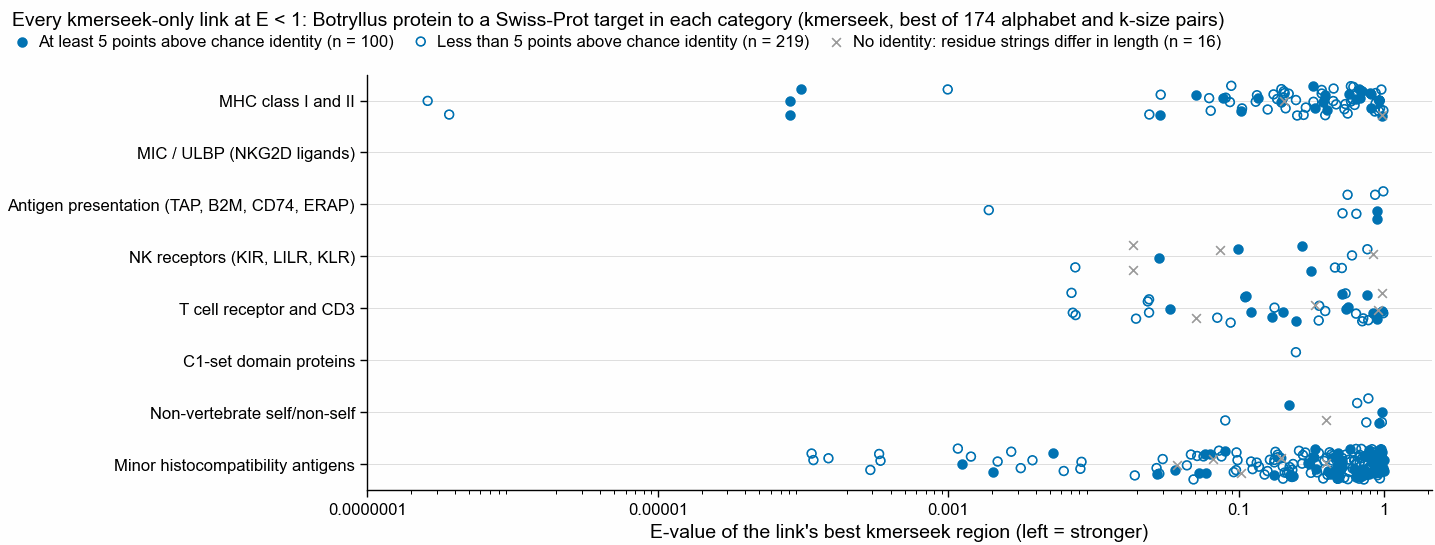

In [11]:
cand = (
    only.filter(pl.col("category") != "control")
    .with_columns(
        order=pl.col("category").map_elements(ORDER.index, return_dtype=pl.Int64),
        query_from=pl.col("region_start") + 1,
        target_from=pl.col("target_start") + 1,
    )
    .sort("order", "region_evalue", "query_name", "target_name")
)
cand_table = cand.select(
    "category",
    "query_name",
    "target_name",
    "target_description",
    "alphabet",
    "ksize",
    "region_evalue",
    "region_length",
    pl.col("query_from"),
    pl.col("region_end").alias("query_to"),
    pl.col("target_from"),
    pl.col("target_end").alias("target_to"),
    (pl.col("identity") * 100).round(1).alias("identity_pct"),
    pl.col("identity_above_chance").round(1),
    (pl.col("letter_identity") * 100).round(1).alias("letter_identity_pct"),
    pl.col("letter_identity_above_chance").round(1),
    "n_alphabets",
    "n_settings",
)
cand_table.write_csv(TABLES / f"281_kmerseek_only_links_E{E_CUTOFF}_{SOURCE}.csv")
print(
    f"{cand_table.height} kmerseek-only links at E < {E_CUTOFF} from "
    f"{cand_table['query_name'].n_unique()} Botryllus proteins to {cand_table['target_name'].n_unique()} targets"
)
print(
    cand_table.group_by("category")
    .agg(
        links=pl.len(),
        botryllus_proteins=pl.col("query_name").n_unique(),
        targets=pl.col("target_name").n_unique(),
        above_chance_by_5=(pl.col("identity_above_chance") >= 5).sum(),
    )
    .with_columns(
        order=pl.col("category").map_elements(ORDER.index, return_dtype=pl.Int64)
    )
    .sort("order")
    .drop("order")
)
with pl.Config(tbl_rows=-1):
    print(cand_table.drop("target_from", "target_to"))

fig, ax = pf.figure(pf.TWO_COLUMN_MM, 70)
above = pl.col("identity_above_chance") >= 5
for selector, label, style in [
    (
        above,
        "At least 5 points above chance identity",
        dict(
            marker="o",
            facecolors=pf.OKABE_ITO["blue"],
            edgecolors=pf.OKABE_ITO["blue"],
            linewidths=0.6,
        ),
    ),
    (
        ~above,
        "Less than 5 points above chance identity",
        dict(
            marker="o",
            facecolors="none",
            edgecolors=pf.OKABE_ITO["blue"],
            linewidths=0.6,
        ),
    ),
    (
        pl.col("identity_above_chance").is_null(),
        "No identity: residue strings differ in length",
        dict(marker="x", color=pf.GREY, linewidths=0.6),
    ),
]:
    s = cand.filter(selector)
    y = np.array([ORDER.index(c) for c in s["category"]]) + np.random.default_rng(
        1
    ).uniform(-0.3, 0.3, s.height)
    ax.scatter(s["region_evalue"], y, s=10, label=f"{label} (n = {s.height})", **style)
ax.set_xscale("log")
ax.set_xticks(
    [1e-7, 1e-5, 1e-3, 1e-1, 1], ["0.0000001", "0.00001", "0.001", "0.1", "1"]
)
ax.set_yticks(range(len(CATEGORIES)), [CATEGORY_NAME[c] for c in CATEGORIES])
ax.set_ylim(len(CATEGORIES) - 0.5, -0.5)
ax.grid(axis="y")
ax.set_xlabel("E-value of the link's best kmerseek region (left = stronger)")
legend_on_top(
    fig,
    f"Every kmerseek-only link at E < {E_CUTOFF}: Botryllus protein to a Swiss-Prot target in each category "
    "(kmerseek, best of 174 alphabet and k-size pairs)",
)
pf.save(fig, FIG / f"281_kmerseek_only_links_evalue_identity_E{E_CUTOFF}_{SOURCE}")

In [12]:
WIDTH = 80


def residue_block(row) -> str:
    q, t = row["region_subseq"], row["target_subseq"]
    head = (
        f"{row['query_name']} {row['region_start'] + 1}-{row['region_end']}  vs  {row['target_name']} "
        f"{row['target_start'] + 1}-{row['target_end']} ({row['target_description']})\n"
        f"  {row['alphabet']} k={row['ksize']}  E={row['region_evalue']:.2g}  {len(q)} aa  "
        + (
            f"identity {row['identity'] * 100:.0f}% (chance {row['chance_identity'] * 100:.0f}%)  "
            if row["identity"] is not None
            else f"chained across an insertion or deletion: Q {len(q)} aa, T {len(t)} aa, not aligned position by position  "
        )
        + (
            f"letter identity {row['letter_identity'] * 100:.0f}% (chance {row['chance_letter_identity'] * 100:.0f}%)  "
            if row["letter_identity"] is not None
            else ""
        )
        + f"alphabets with a region: {row['n_alphabets']}"
    )
    lines = [head] + bmu.residue_lines(
        q, t, row["query_letters"], row["target_letters"], WIDTH
    )
    return "\n".join(lines)


blocks = []
for cat in CATEGORIES:
    c = cand.filter(pl.col("category") == cat)
    if c.height == 0:
        continue
    blocks.append(f"=== {CATEGORY_NAME[cat]}: {c.height} kmerseek-only links ===")
    blocks += [residue_block(r) for r in c.iter_rows(named=True)]
text = "\n\n".join(blocks)
(TABLES / f"281_kmerseek_only_links_residues_E{E_CUTOFF}_{SOURCE}.txt").write_text(
    text + "\n"
)
print(text)

=== MHC class I and II: 76 kmerseek-only links ===

FUN020551_FUN020551.2 2345-2598  vs  P15979 77-330 (Class I histocompatibility antigen, F10 alpha chain)
  hp_lehninger_hpc3 k=17  E=2.6e-07  254 aa  identity 6% (chance 5%)  letter identity 63% (chance 49%)  alphabets with a region: 1
  Q   NTGFIGNLTHCFENPFRYNVTLLDATTLELETSWMTGIILHISLFDSTSVYSNMACQDEANDTRKISISNTRTIISSLSP
  Q a pphhhhphppchpphhphphphhphpphphppphhphhhhphphhpppphhpphhcppphppppphphppppphhpphph
      :: ::   |: ::   ::: : | : : ::::::::  :  : : |  :::   :  : | | |:::: :: |:  :: :
  T a ppphhphppphhphppphpppphhhhppphppphhppphphhhhcphhphhhhphhhphhhphpphphhpphphphphhh
  T   DQQYWDGQTQIGQGNEQIDRENLGILQRRYNQTGGSHTVQWMYGCDILEGGPIRGYYQMAYDGRDFTAFDKGTMTFTAAV
  Q   GNSYFIEGRRDDNNKMLIAEVVGTGRVASPYMKQVDASNSSIRVTWSKSYMGIAFYTTLRGTGYDIFNEQRAWWSPVRGA
  Q a hpphhhphppppppphhhhphhhphphhphhhpphphpppphphphppphhhhhhhpphphphhphhpppphhhphhphh
      :: :: : : ::::::  :: ::: : :::: : |:: : ::  : : :: :::   :: :|:   ::   : : :|:::
  T a hphhhpppph

## 9. BHF and the Botryllus proteins behind most links

BHF (Botryllus histocompatibility factor, gene model FUN008084) is the one Botryllus
allorecognition gene among the queries. The table lists the Botryllus proteins with the
most kmerseek-only links into the eight categories: a protein linked to many unrelated
targets is more likely matching a composition pattern than a family.

BHF (FUN008084) regions on any target or control protein at E < 10, before filtering: 0
┌───────────────────────┬───────┬────────────┬─────────┬─────────────┬──────────────────────────────┬──────────────┬─────────────────────────────────────────────────────────────────────────┐
│ query_name            ┆ links ┆ categories ┆ targets ┆ best_evalue ┆ median_identity_above_chance ┆ query_length ┆ example_targets                                                         │
│ ---                   ┆ ---   ┆ ---        ┆ ---     ┆ ---         ┆ ---                          ┆ ---          ┆ ---                                                                     │
│ str                   ┆ u32   ┆ u32        ┆ u32     ┆ f64         ┆ f64                          ┆ i64          ┆ str                                                                     │
╞═══════════════════════╪═══════╪════════════╪═════════╪═════════════╪══════════════════════════════╪══════════════╪════════════════════════════════

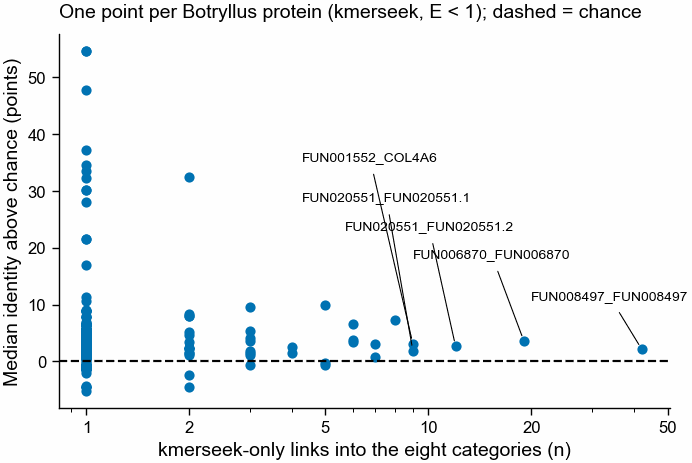

In [13]:
bhf = regions_all.filter(pl.col("query_name").str.starts_with("FUN008084"))
print(
    f"BHF (FUN008084) regions on any target or control protein at E < 10, before filtering: {bhf.height}"
)

top_q = (
    cand.group_by("query_name")
    .agg(
        links=pl.len(),
        categories=pl.col("category").n_unique(),
        targets=pl.col("target_name").n_unique(),
        best_evalue=pl.col("region_evalue").min(),
        median_identity_above_chance=pl.col("identity_above_chance").median(),
        query_length=pl.col("query_length").first(),
        example_targets=pl.col("target_description").unique().head(3).str.join("; "),
    )
    .sort("links", "best_evalue", descending=[True, False])
)
print(top_q.head(15))

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 60)
ax.scatter(
    top_q["links"],
    top_q["median_identity_above_chance"],
    s=10,
    **TOOL_STYLE["kmerseek"],
)
for i, row in enumerate(top_q.head(5).iter_rows(named=True)):
    ax.annotate(
        row["query_name"],
        (row["links"], row["median_identity_above_chance"]),
        xytext=(-40, 18 + 12 * i),
        textcoords="offset points",
        fontsize=5,
        arrowprops=dict(arrowstyle="-", lw=0.4),
    )
ax.axhline(0, color="black", ls="--", lw=0.8)
ax.set_xscale("log")
ax.set_xticks([1, 2, 5, 10, 20, 50], ["1", "2", "5", "10", "20", "50"])
ax.set_xlabel("kmerseek-only links into the eight categories (n)")
ax.set_ylabel("Median identity above chance (points)")
ax.set_title(
    f"One point per Botryllus protein (kmerseek, E < {E_CUTOFF}); dashed = chance",
    loc="left",
)
pf.save(
    fig, FIG / f"281_botryllus_proteins_by_kmerseek_only_links_E{E_CUTOFF}_{SOURCE}"
)

# Summary and conclusions

## Background

Ayelet asked which *Botryllus schlosseri* proteins kmerseek links to MHC, histocompatibility
and self/non-self recognition proteins, and which of those links phmmer, jackhmmer and mmseqs2
miss. This notebook reads the invertebrate dark-set midi run (kmerseek 0.4.0-rc5, 174
alphabet and k-size pairs, scaled 1, low-complexity mask off): Botryllus proteome against
Swiss-Prot minus Ascidiacea, on 826 targets in eight categories and 826 length-matched control
proteins.

## Summary and conclusions

* No category passes the rule: no category has kmerseek-only links on at least 1.5 times the
  share of its targets that length-matched random proteins have, at E < 1.
* MHC class I and II comes closest: 59 of 187 targets (32%) have a kmerseek-only link, against
  22% expected from the control (1.41 times, Bonferroni p = 0.02), under the 1.5-fold bar.
* kmerseek-only links are at chance identity: median 2.7 points above it for the 335 category
  links and 2.9 for the 9_597 control links, against 38 points for links a tool also finds.
* In the alphabet's own letters, kmerseek-only category links match a median 24 points above
  chance, and kmerseek-only links to control proteins 28 points: the letter pattern kmerseek
  scores is as strong on random proteins.
* 98% of kmerseek-only category links appear in one alphabet only, against 28% of links a tool
  also finds; hp_lehninger_hpc3 and gbmr4 give 73% of them.
* The strongest kmerseek-only MHC link, Botryllus FUN020551 to the class I F10 alpha chain
  P15979 (E = 2.6e-7, 254 residues), is 6% identical, 0.1 points above chance.
* jackhmmer reaches 170 of 187 MHC targets (91%, 1.18 times the control), while kmerseek
  reaches 59 after 375 of 521 MHC regions with E < 1 are dropped as low complexity or helix.
* BHF, the one Botryllus allorecognition gene in the query set, has no kmerseek region on
  any of the 1_652 target and control proteins at E < 10.
* At E < 10 no category passes either, and kmerseek-only links match the control's: median 3.4
  points above chance identity for both (5_101 category links, 16_887 control links).

**Decision.** The 335 kmerseek-only links are sent to Ayelet for inspection only, not as leads:
by the rule written first, they occur at the rate kmerseek gives random proteins of the same
length, and their residues match no better than chance. The paper makes no Botryllus MHC claim
from this run.

## Analysis details

* Section 2: dropping regions that are at least half low complexity or transmembrane helix
  removes most regions on MHC (72%), NK receptor (91%), T cell receptor (96%) and minor
  histocompatibility (87%) targets, and 26% on the control. Most dropped MHC and NK-receptor
  regions are both low complexity and helix (MHC: 67% and 60% of its regions); TCR and minor
  histocompatibility regions are dropped for low complexity (94% and 87%).
* Section 3: the tools find Botryllus homologs of the immunoglobulin-fold categories:
  jackhmmer reaches MHC, antigen presentation, NK receptor and TCR targets 1.18 to 1.30 times
  as often as the control (each Bonferroni p < 0.001). kmerseek reaches every recognition
  category less often than the control (0.09 to 0.60 times); only minor histocompatibility
  antigens, ordinary cell proteins, are above it (1.27 times), as for every tool.
* Section 4: at the stricter E < 0.01, minor histocompatibility antigens pass (16 of 204
  targets against 3.5% expected, 2.2 times, p = 0.02) from 18 links of 6 Botryllus proteins;
  no recognition category does. The rule was set at E < 1, so this does not change the decision.
* Section 6: at E < 10 kmerseek-only links reach 184 of 187 MHC targets against 88% expected
  (1.11 times, p < 0.001), T cell receptor targets 1.30 times and NK receptors 1.16 times. At these
  expected shares 1.5-fold cannot be reached (most for MHC: 1.13), so the fold test says little
  here; identity does: 36% of category kmerseek-only links are 5 or more points above chance,
  as are 37% of control ones.
* Section 5: links a tool also finds have median identity 45% (38 points above chance) in the
  categories and 46% in the control; kmerseek-only links have 9% in both. The share of
  kmerseek-only links at least 5 points above chance is 31% in the categories and 32% in the
  control: the above-chance links in the candidate table are what the control predicts.
* Section 8: one Botryllus protein, FUN008497 (281 aa), gives 42 of the 335 kmerseek-only
  links, at a median 2.1 points above chance identity.

## Supplementary information

* Data: `/Users/olga/data/botryllus-mhc/` (copied from `$SCRATCH/botryllus-mhc/` on Sherlock):
  `botryllus_mhc_regions.csv.gz` (870_727 regions with E < 10), `tool_hits_on_targets_E10.tsv`
  (188_855 hits), `mhc_targets.tsv`, `control_targets.tsv`.
* The tool-hit table first made for this notebook (`tool_hits_on_targets.tsv`, 210_746 lines)
  also held 21_891 hits with E > 10 (up to 5.7e5): the stored hit files keep domain hits above
  the reporting cutoff. `scripts/botryllus_tool_hits_on_targets.py` keeps E <= 10 only.
* 16 of the 335 kmerseek-only links have Botryllus and target residue strings of different
  lengths (a region chained across an insertion or deletion); they have no identity value.
* Outputs: `tables/281_*` (targets reached, the decision table, every kmerseek-only link and
  its residues) and `figures/281_*`.

## References

* Invertebrate dark-set run and `tools/dark-regions`:
  [PR 57](https://github.com/seanome/2024-kmerseek-analysis/pull/57).
* Notebook 279, kmerseek's dark-protein regions lean towards low complexity and helices:
  [PR 120](https://github.com/seanome/2024-kmerseek-analysis/pull/120).
* kmerseek alias-target coordinates: [kmerseek PR 141](https://github.com/seanome/kmerseek/pull/141).
* HGNC gene groups, genenames.org, downloaded on the date in `data/hgnc/DOWNLOADED_ON`.

In [14]:
print(r"""
# Summary and conclusions

## Background

Ayelet asked which *Botryllus schlosseri* proteins kmerseek links to MHC, histocompatibility
and self/non-self recognition proteins, and which of those links phmmer, jackhmmer and mmseqs2
miss. This notebook reads the invertebrate dark-set midi run (kmerseek 0.4.0-rc5, 174
alphabet and k-size pairs, scaled 1, low-complexity mask off): Botryllus proteome against
Swiss-Prot minus Ascidiacea, on 826 targets in eight categories and 826 length-matched control
proteins.

## Summary and conclusions

* No category passes the rule: no category has kmerseek-only links on at least 1.5 times the
  share of its targets that length-matched random proteins have, at E < 1.
* MHC class I and II comes closest: 59 of 187 targets (32%) have a kmerseek-only link, against
  22% expected from the control (1.41 times, Bonferroni p = 0.02), under the 1.5-fold bar.
* kmerseek-only links are at chance identity: median 2.7 points above it for the 335 category
  links and 2.9 for the 9_597 control links, against 38 points for links a tool also finds.
* In the alphabet's own letters, kmerseek-only category links match a median 24 points above
  chance, and kmerseek-only links to control proteins 28 points: the letter pattern kmerseek
  scores is as strong on random proteins.
* 98% of kmerseek-only category links appear in one alphabet only, against 28% of links a tool
  also finds; hp_lehninger_hpc3 and gbmr4 give 73% of them.
* The strongest kmerseek-only MHC link, Botryllus FUN020551 to the class I F10 alpha chain
  P15979 (E = 2.6e-7, 254 residues), is 6% identical, 0.1 points above chance.
* jackhmmer reaches 170 of 187 MHC targets (91%, 1.18 times the control), while kmerseek
  reaches 59 after 375 of 521 MHC regions with E < 1 are dropped as low complexity or helix.
* BHF, the one Botryllus allorecognition gene in the query set, has no kmerseek region on
  any of the 1_652 target and control proteins at E < 10.
* At E < 10 no category passes either, and kmerseek-only links match the control's: median 3.4
  points above chance identity for both (5_101 category links, 16_887 control links).

**Decision.** The 335 kmerseek-only links are sent to Ayelet for inspection only, not as leads:
by the rule written first, they occur at the rate kmerseek gives random proteins of the same
length, and their residues match no better than chance. The paper makes no Botryllus MHC claim
from this run.

## Analysis details

* Section 2: dropping regions that are at least half low complexity or transmembrane helix
  removes most regions on MHC (72%), NK receptor (91%), T cell receptor (96%) and minor
  histocompatibility (87%) targets, and 26% on the control. Most dropped MHC and NK-receptor
  regions are both low complexity and helix (MHC: 67% and 60% of its regions); TCR and minor
  histocompatibility regions are dropped for low complexity (94% and 87%).
* Section 3: the tools find Botryllus homologs of the immunoglobulin-fold categories:
  jackhmmer reaches MHC, antigen presentation, NK receptor and TCR targets 1.18 to 1.30 times
  as often as the control (each Bonferroni p < 0.001). kmerseek reaches every recognition
  category less often than the control (0.09 to 0.60 times); only minor histocompatibility
  antigens, ordinary cell proteins, are above it (1.27 times), as for every tool.
* Section 4: at the stricter E < 0.01, minor histocompatibility antigens pass (16 of 204
  targets against 3.5% expected, 2.2 times, p = 0.02) from 18 links of 6 Botryllus proteins;
  no recognition category does. The rule was set at E < 1, so this does not change the decision.
* Section 6: at E < 10 kmerseek-only links reach 184 of 187 MHC targets against 88% expected
  (1.11 times, p < 0.001), T cell receptor targets 1.30 times and NK receptors 1.16 times. At these
  expected shares 1.5-fold cannot be reached (most for MHC: 1.13), so the fold test says little
  here; identity does: 36% of category kmerseek-only links are 5 or more points above chance,
  as are 37% of control ones.
* Section 5: links a tool also finds have median identity 45% (38 points above chance) in the
  categories and 46% in the control; kmerseek-only links have 9% in both. The share of
  kmerseek-only links at least 5 points above chance is 31% in the categories and 32% in the
  control: the above-chance links in the candidate table are what the control predicts.
* Section 8: one Botryllus protein, FUN008497 (281 aa), gives 42 of the 335 kmerseek-only
  links, at a median 2.1 points above chance identity.

## Supplementary information

* Data: `/Users/olga/data/botryllus-mhc/` (copied from `$SCRATCH/botryllus-mhc/` on Sherlock):
  `botryllus_mhc_regions.csv.gz` (870_727 regions with E < 10), `tool_hits_on_targets_E10.tsv`
  (188_855 hits), `mhc_targets.tsv`, `control_targets.tsv`.
* The tool-hit table first made for this notebook (`tool_hits_on_targets.tsv`, 210_746 lines)
  also held 21_891 hits with E > 10 (up to 5.7e5): the stored hit files keep domain hits above
  the reporting cutoff. `scripts/botryllus_tool_hits_on_targets.py` keeps E <= 10 only.
* 16 of the 335 kmerseek-only links have Botryllus and target residue strings of different
  lengths (a region chained across an insertion or deletion); they have no identity value.
* Outputs: `tables/281_*` (targets reached, the decision table, every kmerseek-only link and
  its residues) and `figures/281_*`.

## References

* Invertebrate dark-set run and `tools/dark-regions`:
  [PR 57](https://github.com/seanome/2024-kmerseek-analysis/pull/57).
* Notebook 279, kmerseek's dark-protein regions lean towards low complexity and helices:
  [PR 120](https://github.com/seanome/2024-kmerseek-analysis/pull/120).
* kmerseek alias-target coordinates: [kmerseek PR 141](https://github.com/seanome/kmerseek/pull/141).
* HGNC gene groups, genenames.org, downloaded on the date in `data/hgnc/DOWNLOADED_ON`.
""")


# Summary and conclusions

## Background

Ayelet asked which *Botryllus schlosseri* proteins kmerseek links to MHC, histocompatibility
and self/non-self recognition proteins, and which of those links phmmer, jackhmmer and mmseqs2
miss. This notebook reads the invertebrate dark-set midi run (kmerseek 0.4.0-rc5, 174
alphabet and k-size pairs, scaled 1, low-complexity mask off): Botryllus proteome against
Swiss-Prot minus Ascidiacea, on 826 targets in eight categories and 826 length-matched control
proteins.

## Summary and conclusions

* No category passes the rule: no category has kmerseek-only links on at least 1.5 times the
  share of its targets that length-matched random proteins have, at E < 1.
* MHC class I and II comes closest: 59 of 187 targets (32%) have a kmerseek-only link, against
  22% expected from the control (1.41 times, Bonferroni p = 0.02), under the 1.5-fold bar.
* kmerseek-only links are at chance identity: median 2.7 points above it for the 335 category
  links and